# Day 1 — Document Ingestion & Layout Parsing

## 1. Install dependencies

Install the PDF parsing, rendering, OCR, image, and data-handling libraries used in this notebook.

In [1]:
!apt-get -qq update
!apt-get -qq install -y poppler-utils tesseract-ocr
!pip -q install "unstructured[pdf]" pymupdf pillow pandas matplotlib

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package poppler-utils.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../poppler-utils_24.02.0-1ubuntu9.11_amd64.deb ...
Unpacking poppler-utils (24.02.0-1ubuntu9.11) ...
Setting up poppler-utils (24.02.0-1ubuntu9.11) ...
Processing triggers for man-db (2.12.0-4build2) ...
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


## 2. Imports

Import the libraries needed to read PDFs, parse their layout, inspect images, and save structured results.

In [2]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import fitz
from unstructured.partition.pdf import partition_pdf

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


## 3. Upload a PDF

Upload a PDF document that contains text, tables, scanned pages, or figures.

In [3]:
from google.colab import files

uploaded = files.upload()
pdf_files = [name for name in uploaded if name.lower().endswith(".pdf")]
if not pdf_files:
    raise ValueError("Upload at least one PDF file.")

pdf_path = Path(pdf_files[0])
print("Using:", pdf_path.name)

Saving sample_multimodal_invoice.pdf to sample_multimodal_invoice.pdf
Using: sample_multimodal_invoice.pdf


## 4. Render PDF pages

Convert each PDF page into an image so its visual layout can be inspected.

In [4]:
render_dir = Path("rendered_pages")
render_dir.mkdir(exist_ok=True)
doc = fitz.open(pdf_path)
page_images = []

for page_number, page in enumerate(doc, start=1):
    pix = page.get_pixmap(matrix=fitz.Matrix(2, 2), alpha=False)
    image_path = render_dir / f"page_{page_number}.png"
    pix.save(image_path)
    page_images.append(image_path)

print(f"Rendered {len(page_images)} page(s).")

Rendered 2 page(s).


## 5. Parse text, tables and layout

Use Unstructured's high-resolution strategy to identify document elements and extract layout information.

In [5]:
image_dir = Path("extracted_images")
image_dir.mkdir(exist_ok=True)

elements = partition_pdf(
    filename=str(pdf_path),
    strategy="hi_res",
    infer_table_structure=True,
    extract_images_in_pdf=True,
    extract_image_block_types=["Image", "Table"],
    extract_image_block_output_dir=str(image_dir)
)
print("Extracted elements:", len(elements))

yolox_l0.05.onnx: reconstructing file:   0%|          |  0.00B /  217MB            

yolox_l0.05.onnx: downloading bytes:           |  0.00B            

preprocessor_config.json:   0%|          | 0.00/274 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.47k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  115MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/367 [00:00<?, ?it/s]

Extracted elements: 35


## 6. Convert elements to structured records

Convert each extracted element into a record with its type, text, page, source filename, and bounding box.

In [6]:
def element_record(element, index):
    metadata = element.metadata
    coordinates = metadata.coordinates
    bbox = None

    if coordinates is not None:
        points = coordinates.points
        xs = [point[0] for point in points]
        ys = [point[1] for point in points]
        bbox = {"x1": min(xs), "y1": min(ys), "x2": max(xs), "y2": max(ys)}

    category = element.category
    element_type = "table" if category == "Table" else (
        "image" if category == "Image" else category.lower()
    )

    return {
        "element_id": index,
        "source_doc": pdf_path.name,
        "page": metadata.page_number,
        "type": element_type,
        "text": str(element),
        "bbox": bbox,
        "element_category": category
    }

records = [element_record(element, i) for i, element in enumerate(elements)]
elements_df = pd.DataFrame(records)
elements_df.head(10)

,element_id,source_doc,page,type,text,bbox,element_category
0,0,sample_multimodal_invoice.pdf,1,image,MERIDIAN RESEARCH LABS,"{'x1': 290.9777013888889, 'y1': 264.2224375000...",Image
1,1,sample_multimodal_invoice.pdf,1,title,TAX INVOICE,"{'x1': 2282.110107421875, 'y1': 346.8571458333...",Title
2,2,sample_multimodal_invoice.pdf,1,narrativetext,Original for recipient,"{'x1': 2207.908447265625, 'y1': 409.0453402777...",NarrativeText
3,3,sample_multimodal_invoice.pdf,1,uncategorizedtext,Supplier,"{'x1': 307.0, 'y1': 651.0, 'x2': 499.0, 'y2': ...",UncategorizedText
4,4,sample_multimodal_invoice.pdf,1,title,Supplier,"{'x1': 305.5610347222222, 'y1': 652.7626388888...",Title
5,5,sample_multimodal_invoice.pdf,1,narrativetext,"Meridian Research Labs Pvt. Ltd. Plot 18, Sect...","{'x1': 299.601318359375, 'y1': 691.32629394531...",NarrativeText
6,6,sample_multimodal_invoice.pdf,1,title,Bill To,"{'x1': 1490.600270833333, 'y1': 652.7626388888...",Title
7,7,sample_multimodal_invoice.pdf,1,narrativetext,"Northstar Office Supplies Unit 402, Tech Park ...","{'x1': 1480.69482421875, 'y1': 709.23321533203...",NarrativeText
8,8,sample_multimodal_invoice.pdf,1,table,Invoice No. MRL-2026-1184 Invoice Date 18 Nov ...,"{'x1': 280.1124267578125, 'y1': 1085.427001953...",Table
9,9,sample_multimodal_invoice.pdf,1,title,Items and Services,"{'x1': 271.5218200683594, 'y1': 1435.656738281...",Title


## 7. Check extracted element types

Review the number and types of elements detected and inspect sample extracted content.

In [7]:
display(elements_df["type"].value_counts().rename_axis("type").reset_index(name="count"))
display(elements_df[["element_id", "page", "type", "element_category", "text"]].head(20))

,type,count
0,narrativetext,15
1,title,10
2,table,5
3,uncategorizedtext,4
4,image,1


,element_id,page,type,element_category,text
0,0,1,image,Image,MERIDIAN RESEARCH LABS
1,1,1,title,Title,TAX INVOICE
2,2,1,narrativetext,NarrativeText,Original for recipient
3,3,1,uncategorizedtext,UncategorizedText,Supplier
4,4,1,title,Title,Supplier
5,5,1,narrativetext,NarrativeText,"Meridian Research Labs Pvt. Ltd. Plot 18, Sect..."
6,6,1,title,Title,Bill To
7,7,1,narrativetext,NarrativeText,"Northstar Office Supplies Unit 402, Tech Park ..."
8,8,1,table,Table,Invoice No. MRL-2026-1184 Invoice Date 18 Nov ...
9,9,1,title,Title,Items and Services


## 8. Inspect page layout

Display a rendered page to visually check the original document layout.

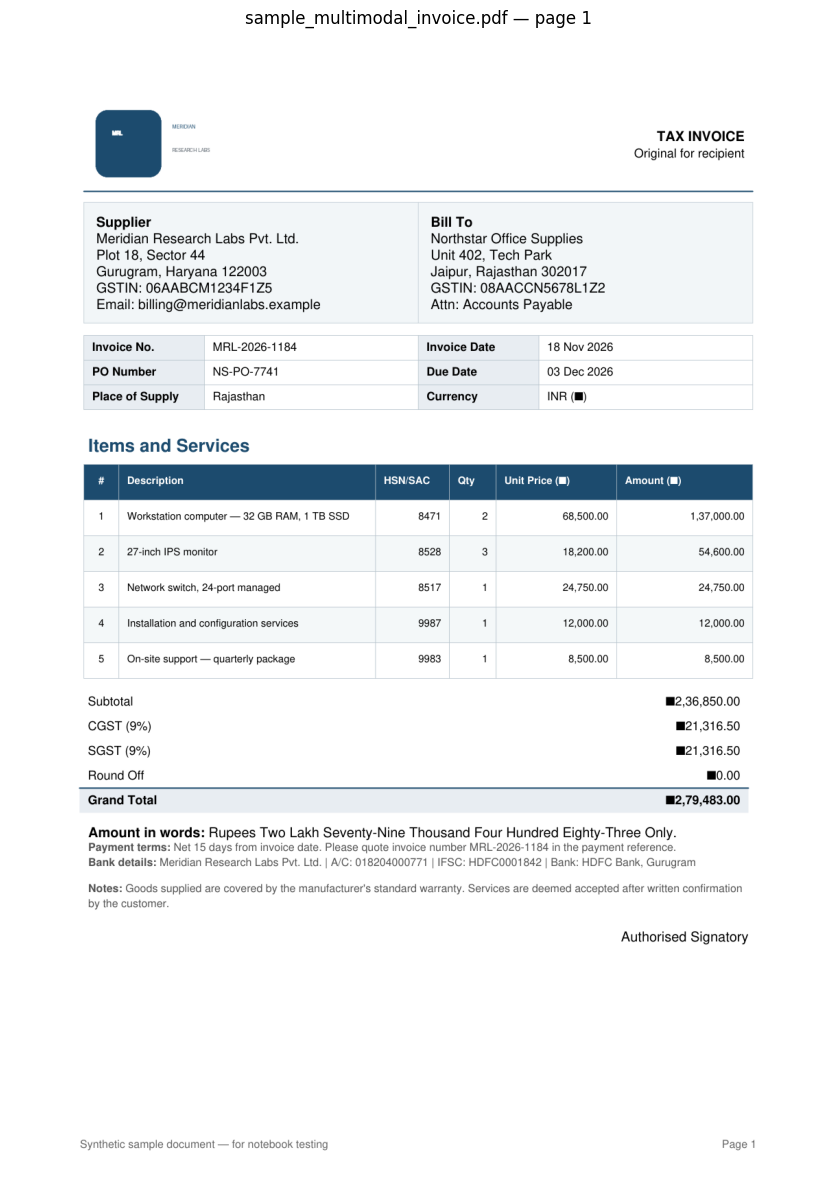

In [8]:
page_to_view = 1
if not 1 <= page_to_view <= len(page_images):
    raise ValueError("page_to_view is outside the PDF page range.")

page_image = Image.open(page_images[page_to_view - 1])
plt.figure(figsize=(12, 15))
plt.imshow(page_image)
plt.axis("off")
plt.title(f"{pdf_path.name} — page {page_to_view}")
plt.show()

## 9. Draw extracted bounding boxes

Overlay the parser's bounding boxes on the page image to see where detected elements are located.

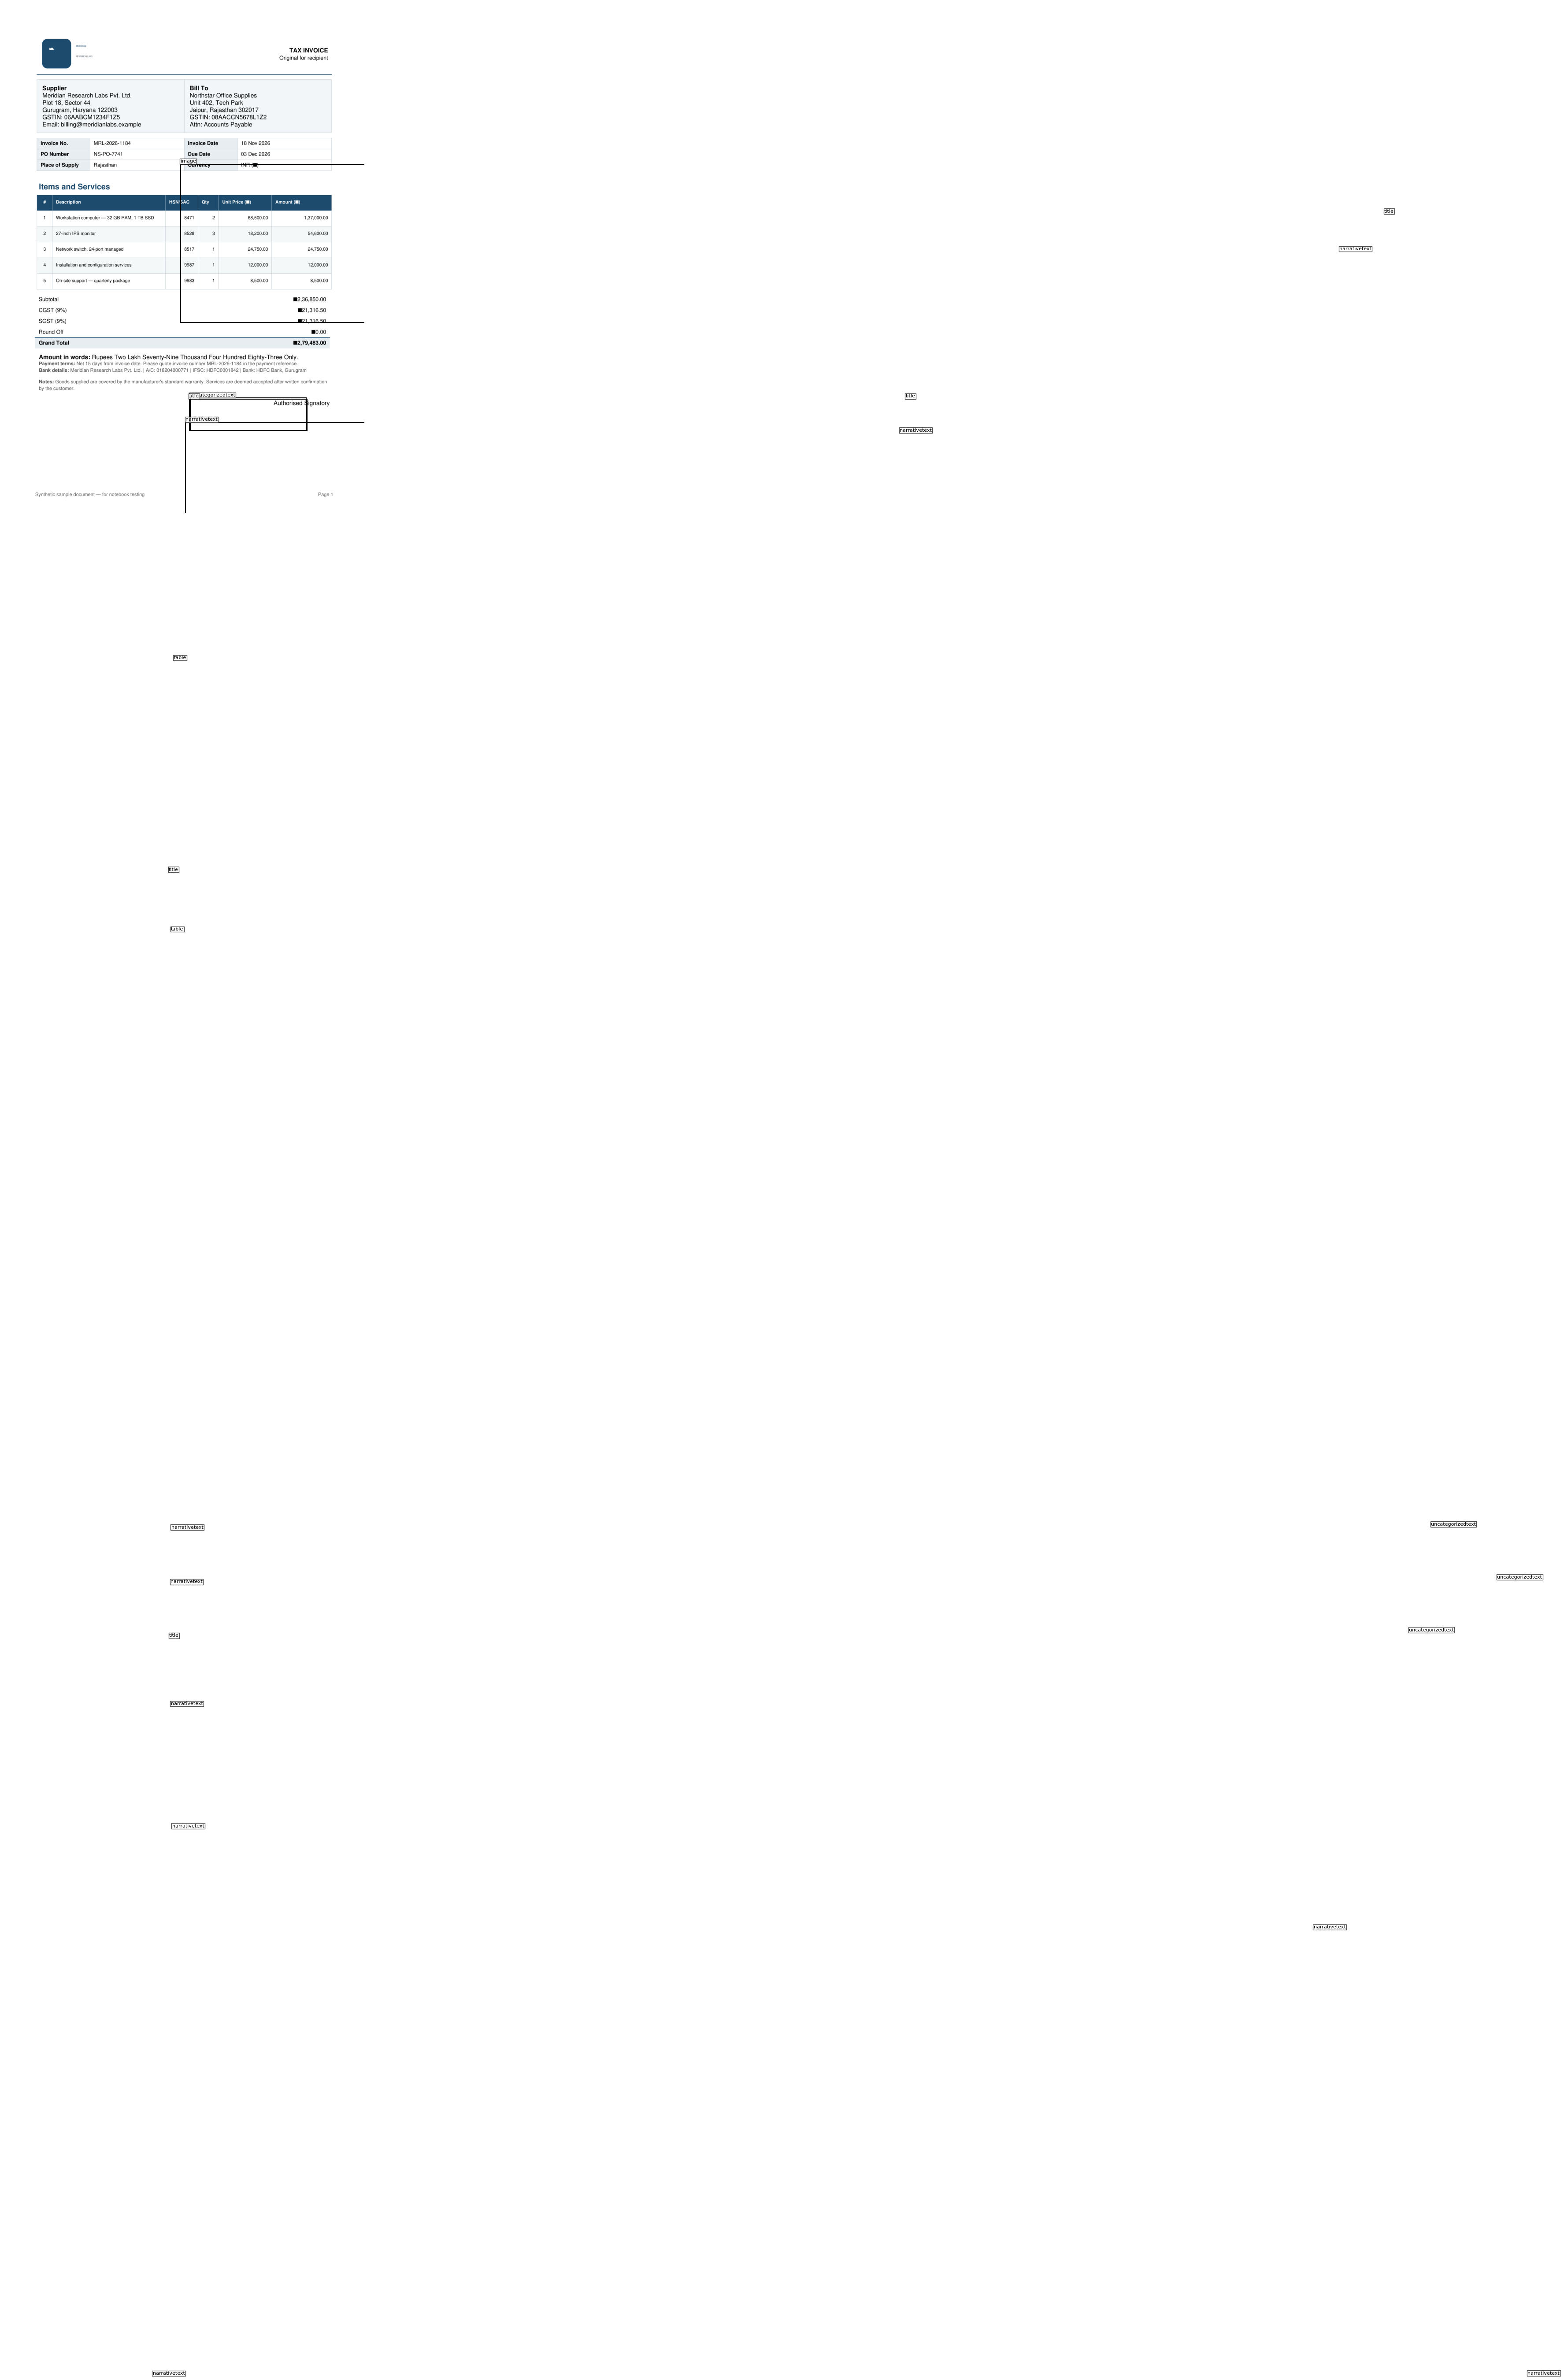

Elements with bounding boxes: 22


In [9]:
page = doc[page_to_view - 1]
scale_x = page_image.width / page.rect.width
scale_y = page_image.height / page.rect.height
page_elements = [r for r in records if r["page"] == page_to_view and r["bbox"]]

fig, ax = plt.subplots(figsize=(12, 15))
ax.imshow(page_image)

for record in page_elements:
    box = record["bbox"]
    x1, y1 = box["x1"] * scale_x, box["y1"] * scale_y
    x2, y2 = box["x2"] * scale_x, box["y2"] * scale_y
    ax.add_patch(plt.Rectangle((x1, y1), x2-x1, y2-y1, fill=False, linewidth=1.5))
    ax.text(x1, max(0, y1-5), record["type"], fontsize=8,
            bbox={"facecolor": "white", "alpha": 0.7, "pad": 1})

ax.axis("off")
plt.show()
print("Elements with bounding boxes:", len(page_elements))

## 10. Inspect extracted tables

Review the table elements and their extracted text.

In [10]:
table_records = [r for r in records if r["type"] == "table"]
print("Tables found:", len(table_records))

for number, table in enumerate(table_records, start=1):
    print(f"\\nTable {number} | page {table['page']}")
    print(table["text"][:1500])

Tables found: 5
\nTable 1 | page 1
Invoice No. MRL-2026-1184 Invoice Date 18 Nov 2026 PO Number NS-PO-7741 Due Date 03 Dec 2026 Place of Supply Rajasthan Currency INR (n)
\nTable 2 | page 1
# Description HSN/SAC Qty Unit Price (n) Amount (n) 1 Workstation computer — 32 GB RAM, 1 TB SSD 8471 2 68,500.00 1,37,000.00 2 27-inch IPS monitor 8528 3 18,200.00 54,600.00 3 Network switch, 24-port managed 8517 1 24,750.00 24,750.00 4 Installation and configuration services 9987 1 12,000.00 12,000.00 5 On-site support — quarterly package 9983 1 8,500.00 8,500.00 Subtotal n2,36,850.00 CGST (9%) n21,316.50
\nTable 3 | page 2
Delivery Ref. Item Delivery Date Location Status DLV-8812 Workstations (2 units) 17 Nov 2026 Jaipur office Delivered DLV-8813 Monitors (3 units) 17 Nov 2026 Jaipur office Delivered DLV-8814 24-port network switch 18 Nov 2026 Jaipur office Delivered
\nTable 4 | page 2
Service Work performed Hours Completion Installation Unpacking, hardware checks, workstation setup and OS config

## 11. Save structured output

Save all extracted elements and metadata as JSON and CSV files.

In [11]:
output = {
    "source_doc": pdf_path.name,
    "page_count": len(doc),
    "element_count": len(records),
    "elements": records
}

json_path = Path("day1_document_elements.json")
with open(json_path, "w", encoding="utf-8") as file:
    json.dump(output, file, ensure_ascii=False, indent=2, default=str)

csv_path = Path("day1_document_elements.csv")
elements_df.to_csv(csv_path, index=False)

print("Saved:", json_path)
print("Saved:", csv_path)

Saved: day1_document_elements.json
Saved: day1_document_elements.csv


## 12. Download outputs

Download the JSON and CSV outputs for later use in the multimodal RAG pipeline.

In [12]:
files.download(str(json_path))
files.download(str(csv_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Notebook summary
This notebook ingests a PDF and renders its pages for visual inspection. It uses Unstructured to identify text, tables, images, and other layout elements, then records each element with its source document, page number, type, text, and bounding-box coordinates where available. The extracted layout is inspected visually, and the structured results are exported as JSON and CSV for use in later retrieval steps.